In [1]:
from pathlib import Path
import json
import gc
import time
import random
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(
    r"C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence"
)

DATA_DIR = PROJECT_ROOT / "data" / "processed"
LSTM_DATA_DIR = DATA_DIR / "lstm"
TFT_DATA_DIR = DATA_DIR / "tft"
LGB_DATA_DIR = DATA_DIR / "lightgbm_corrected"

OUTPUT_DIR = DATA_DIR / "model_comparison"
PREDICTION_DIR = OUTPUT_DIR / "predictions"
RESULT_DIR = PROJECT_ROOT / "results" / "model_comparison"
MODEL_DIR = PROJECT_ROOT / "models" / "internal_test"

for path in [PREDICTION_DIR, RESULT_DIR, MODEL_DIR]:
    path.mkdir(parents=True, exist_ok=True)

TEST_ORIGIN = 1885
TEST_START = 1886
TEST_END = 1913
FORECAST_HORIZON = 28

# Locate the LSTM internal-test evaluation file.
lstm_eval_candidates = list(
    (LSTM_DATA_DIR / "processed_datasets").glob(
        "*internal_test*"
    )
)


assert lstm_eval_candidates, "No internal-test LSTM files found."

### Model Evaluation using Test Set

#### Seasonal Naive

In [11]:
import duckdb

LSTM_EVAL_PATH = next(
    p for p in lstm_eval_candidates
    if "evaluation" in p.name.lower()
)

with np.load(LSTM_EVAL_PATH, allow_pickle=False) as data:
    SERIES_IDS = data["series_ids"].astype(str)

assert len(SERIES_IDS) == 200
assert len(set(SERIES_IDS)) == 200

series_id_sql = ",".join(
    "'" + x.replace("'", "''") + "'"
    for x in SERIES_IDS
)

DAILY_PANEL_PATH = DATA_DIR / "daily_model_features.parquet"

assert DAILY_PANEL_PATH.exists(), DAILY_PANEL_PATH

daily = duckdb.query(f"""
    SELECT
        CAST(id AS VARCHAR) AS id,
        CAST(SUBSTRING(d, 3) AS INTEGER) AS day_num,
        sales
    FROM read_parquet('{DAILY_PANEL_PATH.as_posix()}')
    WHERE CAST(id AS VARCHAR) IN ({series_id_sql})
      AND CAST(SUBSTRING(d, 3) AS INTEGER)
          BETWEEN {TEST_ORIGIN - 6} AND {TEST_END}
    ORDER BY id, day_num
""").df()

assert daily["id"].nunique() == 200
assert not daily.duplicated(["id", "day_num"]).any()

rows = []

for series_id, group in daily.groupby("id", sort=False):

    group = group.sort_values("day_num")

    history = group[
        group["day_num"].between(TEST_ORIGIN - 6, TEST_ORIGIN)
    ]["sales"].to_numpy(dtype=float)

    actuals = group[
        group["day_num"].between(TEST_START, TEST_END)
    ].sort_values("day_num")["sales"].to_numpy(dtype=float)

    assert len(history) == 7, f"Missing history for {series_id}"
    assert len(actuals) == 28, f"Missing actuals for {series_id}"

    for horizon in range(1, 29):

        forecast = history[(horizon - 1) % 7]

        rows.append({
            "id": series_id,
            "origin_day_num": TEST_ORIGIN,
            "target_day_num": TEST_ORIGIN + horizon,
            "horizon": horizon,
            "y_true": actuals[horizon - 1],
            "p10": np.nan,
            "p50": forecast,
            "p90": np.nan
        })

naive_predictions = pd.DataFrame(rows)

naive_path = PREDICTION_DIR / "seasonal_naive_internal_test.parquet"
naive_predictions.to_parquet(naive_path, index=False)

print("Seasonal Naive predictions:", naive_predictions.shape)
print("Unique series:", naive_predictions["id"].nunique())
print("Saved:", naive_path)

assert len(naive_predictions) == 200 * 28
assert naive_predictions["p50"].notna().all()

Seasonal Naive predictions: (5600, 8)
Unique series: 200
Saved: C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\processed\model_comparison\predictions\seasonal_naive_internal_test.parquet


#### LightGBM Quantile Regression

In [12]:
import lightgbm as lgb

LGB_CONFIG_PATH = (
    PROJECT_ROOT / "models" / "lightgbm" /
    "artifacts" / "lightgbm_model_config.json"
)

LGB_TRAIN_PATH = LGB_DATA_DIR / "fold_4_train.parquet"
LGB_VALIDATION_PATH = LGB_DATA_DIR / "fold_4_validation.parquet"

assert LGB_CONFIG_PATH.exists()
assert LGB_TRAIN_PATH.exists()
assert LGB_VALIDATION_PATH.exists()

with open(LGB_CONFIG_PATH, "r", encoding="utf-8") as f:
    lgb_config = json.load(f)

MODEL_FEATURES = lgb_config["model_features"]
CATEGORICAL_FEATURES = lgb_config["categorical_features"]
TARGET_COLUMN = lgb_config["target_column"]

print("Features:", len(MODEL_FEATURES))
print("Categorical features:", CATEGORICAL_FEATURES)
print("Target:", TARGET_COLUMN)

# Read only the common 200 series using DuckDB.
train_lgb = duckdb.query(f"""
    SELECT *
    FROM read_parquet('{LGB_TRAIN_PATH.as_posix()}')
    WHERE CAST(id AS VARCHAR) IN ({series_id_sql})
""").df()

validation_lgb = duckdb.query(f"""
    SELECT *
    FROM read_parquet('{LGB_VALIDATION_PATH.as_posix()}')
    WHERE CAST(id AS VARCHAR) IN ({series_id_sql})
      AND origin_day_num = {TEST_ORIGIN}
""").df()

print("Training rows:", len(train_lgb))
print("Validation rows:", len(validation_lgb))
print("Training series:", train_lgb["id"].nunique())
print("Validation series:", validation_lgb["id"].nunique())

assert train_lgb["id"].nunique() == 200
assert validation_lgb["id"].nunique() == 200
assert len(validation_lgb) == 200 * 28
assert train_lgb[TARGET_COLUMN].notna().all()
assert validation_lgb[TARGET_COLUMN].notna().all()

Features: 32
Categorical features: ['item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'target_weekday', 'target_event_name_1', 'target_event_type_1']
Target: target_sales
Training rows: 1461600
Validation rows: 5600
Training series: 200
Validation series: 200


In [13]:
# Train the three LightGBM quantile models
LGB_QUANTILES = [0.1, 0.5, 0.9]

LGB_FIXED_ROUNDS = {
    0.1: 110,
    0.5: 175,
    0.9: 380
}

LGB_BASE_PARAMS = {
    "objective": "quantile",
    "learning_rate": 0.05,
    "num_leaves": 31,
    "max_depth": -1,
    "min_child_samples": 100,
    "feature_fraction": 0.9,
    "verbosity": -1,
    "seed": 42,
    "n_jobs": -1
}

X_train = train_lgb[MODEL_FEATURES].copy()
y_train = train_lgb[TARGET_COLUMN].astype(float)

X_validation = validation_lgb[MODEL_FEATURES].copy()

# Ensure categorical dtypes and category mappings are consistent.
for column in CATEGORICAL_FEATURES:

    categories = pd.Index(
        X_train[column].dropna().unique()
    )

    X_train[column] = pd.Categorical(
        X_train[column],
        categories=categories
    )

    X_validation[column] = pd.Categorical(
        X_validation[column],
        categories=categories
    )

assert all(
    isinstance(X_train[c].dtype, pd.CategoricalDtype)
    for c in CATEGORICAL_FEATURES
)

lgb_models = {}
lgb_predictions = {}

for quantile in LGB_QUANTILES:

    print(f"\nTraining LightGBM quantile: {quantile}")

    params = {
        **LGB_BASE_PARAMS,
        "alpha": quantile
    }

    train_dataset = lgb.Dataset(
        X_train,
        label=y_train,
        categorical_feature=CATEGORICAL_FEATURES,
        free_raw_data=False
    )

    model = lgb.train(
        params=params,
        train_set=train_dataset,
        num_boost_round=LGB_FIXED_ROUNDS[quantile]
    )

    prediction = model.predict(X_validation)

    lgb_models[quantile] = model
    lgb_predictions[quantile] = prediction

    model_path = (
        MODEL_DIR / f"lightgbm_p{int(quantile * 100)}.txt"
    )

    model.save_model(str(model_path))

    print(
        f"Quantile {quantile}: "
        f"{LGB_FIXED_ROUNDS[quantile]} rounds"
    )
    print("Saved:", model_path)


Training LightGBM quantile: 0.1
Quantile 0.1: 110 rounds
Saved: C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\models\internal_test\lightgbm_p10.txt

Training LightGBM quantile: 0.5
Quantile 0.5: 175 rounds
Saved: C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\models\internal_test\lightgbm_p50.txt

Training LightGBM quantile: 0.9
Quantile 0.9: 380 rounds
Saved: C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\models\internal_test\lightgbm_p90.txt


In [14]:
# Export LightGBM predictions
lgb_output = validation_lgb[
    ["id", "origin_day_num", "target_day_num", "horizon", TARGET_COLUMN]
].copy()

lgb_output = lgb_output.rename(
    columns={TARGET_COLUMN: "y_true"}
)

lgb_output["id"] = lgb_output["id"].astype(str)
lgb_output["p10"] = lgb_predictions[0.1]
lgb_output["p50"] = lgb_predictions[0.5]
lgb_output["p90"] = lgb_predictions[0.9]

lgb_path = PREDICTION_DIR / "lightgbm_internal_test.parquet"
lgb_output.to_parquet(lgb_path, index=False)

print(lgb_output.head())
print("Shape:", lgb_output.shape)
print("Saved:", lgb_path)

assert len(lgb_output) == 5600
assert lgb_output[["p10", "p50", "p90"]].notna().all().all()

                            id  origin_day_num  target_day_num  horizon  \
0  FOODS_3_339_CA_1_evaluation            1885            1886        1   
1  FOODS_3_339_CA_1_evaluation            1885            1887        2   
2  FOODS_3_339_CA_1_evaluation            1885            1888        3   
3  FOODS_3_339_CA_1_evaluation            1885            1889        4   
4  FOODS_3_339_CA_1_evaluation            1885            1890        5   

   y_true       p10       p50        p90  
0       7  0.655159  4.593938  11.395696  
1      10  0.655159  4.239145  10.717981  
2       8  0.655159  4.239145  10.724299  
3      13  0.655159  4.239145  10.724299  
4       6  0.655159  5.059871  12.488564  
Shape: (5600, 8)
Saved: C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\processed\model_comparison\predictions\lightgbm_internal_test.parquet


#### LSTM

In [ ]:
import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

# Load LSTM internal-test datasets
LSTM_PROCESSED_DIR = LSTM_DATA_DIR / "processed_datasets"

LSTM_TRAIN_PATH = LSTM_PROCESSED_DIR / "internal_test_train.npz"
LSTM_EVAL_PATH = LSTM_PROCESSED_DIR / "internal_test_evaluation.npz"

assert LSTM_TRAIN_PATH.exists(), LSTM_TRAIN_PATH
assert LSTM_EVAL_PATH.exists(), LSTM_EVAL_PATH

print("Training file:", LSTM_TRAIN_PATH)
print("Evaluation file:", LSTM_EVAL_PATH)

def load_lstm_arrays(path):
    with np.load(path, allow_pickle=False) as data:
        return {key: data[key].copy() for key in data.files}

lstm_train_arrays = load_lstm_arrays(LSTM_TRAIN_PATH)
lstm_eval_arrays = load_lstm_arrays(LSTM_EVAL_PATH)

print("Training arrays:")
for key, value in lstm_train_arrays.items():
    print(key, value.shape, value.dtype)

print("\nEvaluation arrays:")
for key, value in lstm_eval_arrays.items():
    print(key, value.shape, value.dtype)

assert np.array_equal(
    lstm_eval_arrays["series_ids"].astype(str),
    SERIES_IDS
)

assert int(lstm_eval_arrays["evaluation_origin"]) == TEST_ORIGIN

Training file: C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\processed\lstm\processed_datasets\internal_test_train.npz
Evaluation file: C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\processed\lstm\processed_datasets\internal_test_evaluation.npz
Training arrays:
historical_numeric (52200, 56, 14) float32
historical_categorical (52200, 56, 3) int64
future_numeric (52200, 28, 9) float32
future_categorical (52200, 28, 3) int64
static_categorical (52200, 5) int64
target_sales (52200, 28) float32
series_ids (52200,) <U31
origins (52200,) int64

Evaluation arrays:
historical_numeric (200, 56, 14) float32
historical_categorical (200, 56, 3) int64
future_numeric (200, 28, 9) float32
future_categorical (200, 28, 3) int64
static_categorical (200, 5) int64
target_sales (200, 28) float32
series_ids (200,) <U31
evaluation_origin () int64


In [ ]:
# Define the LSTM dataset and loss
class RetailDemandDataset(Dataset):

    def __init__(self, arrays):

        self.historical_numeric = torch.tensor(
            arrays["historical_numeric"], dtype=torch.float32
        )
        self.historical_categorical = torch.tensor(
            arrays["historical_categorical"], dtype=torch.long
        )
        self.future_numeric = torch.tensor(
            arrays["future_numeric"], dtype=torch.float32
        )
        self.future_categorical = torch.tensor(
            arrays["future_categorical"], dtype=torch.long
        )
        self.static_categorical = torch.tensor(
            arrays["static_categorical"], dtype=torch.long
        )
        self.target_sales = torch.tensor(
            arrays["target_sales"], dtype=torch.float32
        )

    def __len__(self):
        return len(self.target_sales)

    def __getitem__(self, index):
        return (
            self.historical_numeric[index],
            self.historical_categorical[index],
            self.future_numeric[index],
            self.future_categorical[index],
            self.static_categorical[index],
            self.target_sales[index]
        )


class QuantileLoss(nn.Module):

    def __init__(self, quantiles):
        super().__init__()
        self.register_buffer(
            "quantiles",
            torch.tensor(quantiles, dtype=torch.float32)
        )

    def forward(self, predictions, targets):
        errors = targets.unsqueeze(-1) - predictions
        q = self.quantiles.view(1, 1, -1)

        return torch.maximum(
            q * errors,
            (q - 1.0) * errors
        ).mean()


class RetailDemandLSTM(nn.Module):

    def __init__(
        self,
        historical_numeric_dim,
        historical_categorical_cardinalities,
        future_numeric_dim,
        future_categorical_cardinalities,
        static_categorical_cardinalities,
        hidden_size=128,
        num_layers=2,
        dropout=0.15,
        quantiles=(0.1, 0.5, 0.9)
    ):
        super().__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.quantiles = list(quantiles)

        def create_embeddings(cardinalities):
            embeddings = nn.ModuleList()

            for cardinality in cardinalities:
                embedding_dim = min(
                    32,
                    max(4, int(round(cardinality ** 0.5 * 2)))
                )

                embeddings.append(
                    nn.Embedding(
                        num_embeddings=cardinality,
                        embedding_dim=embedding_dim,
                        padding_idx=0
                    )
                )

            return embeddings

        self.historical_embeddings = create_embeddings(
            historical_categorical_cardinalities
        )

        self.future_embeddings = create_embeddings(
            future_categorical_cardinalities
        )

        self.static_embeddings = create_embeddings(
            static_categorical_cardinalities
        )

        historical_embedding_dim = sum(
            embedding.embedding_dim
            for embedding in self.historical_embeddings
        )

        future_embedding_dim = sum(
            embedding.embedding_dim
            for embedding in self.future_embeddings
        )

        static_embedding_dim = sum(
            embedding.embedding_dim
            for embedding in self.static_embeddings
        )

        encoder_input_dim = (
            historical_numeric_dim + historical_embedding_dim
        )

        decoder_input_dim = (
            future_numeric_dim
            + future_embedding_dim
            + static_embedding_dim
        )

        self.encoder = nn.LSTM(
            input_size=encoder_input_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.decoder = nn.LSTM(
            input_size=decoder_input_dim,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.output_dropout = nn.Dropout(dropout)

        self.quantile_head = nn.Linear(
            hidden_size,
            len(self.quantiles)
        )

    @staticmethod
    def embed_categorical(inputs, embedding_layers):
        embedded = []

        for feature_index, embedding_layer in enumerate(
            embedding_layers
        ):
            embedded.append(
                embedding_layer(
                    inputs[..., feature_index].long()
                )
            )

        return torch.cat(embedded, dim=-1)

    def forward(
        self,
        historical_numeric,
        historical_categorical,
        future_numeric,
        future_categorical,
        static_categorical
    ):

        historical_embedded = self.embed_categorical(
            historical_categorical,
            self.historical_embeddings
        )

        future_embedded = self.embed_categorical(
            future_categorical,
            self.future_embeddings
        )

        static_embedded = self.embed_categorical(
            static_categorical,
            self.static_embeddings
        )

        encoder_input = torch.cat(
            [
                historical_numeric.float(),
                historical_embedded
            ],
            dim=-1
        )

        _, (hidden_state, cell_state) = self.encoder(
            encoder_input
        )

        static_context = static_embedded.unsqueeze(1).expand(
            -1,
            future_numeric.size(1),
            -1
        )

        decoder_input = torch.cat(
            [
                future_numeric.float(),
                future_embedded,
                static_context
            ],
            dim=-1
        )

        decoder_output, _ = self.decoder(
            decoder_input,
            (hidden_state, cell_state)
        )

        decoder_output = self.output_dropout(decoder_output)

        predictions = self.quantile_head(decoder_output)

        return predictions



In [ ]:
# Define the baseline LSTM architecture
LSTM_PARAMS = {
    "hidden_size": 128,
    "num_layers": 2,
    "dropout": 0.15,
    "batch_size": 256,
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,
    "epochs": 11,
    "quantiles": [0.1, 0.5, 0.9]
}

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

def get_cardinalities(array):
    return [
        int(array[..., i].max()) + 1
        for i in range(array.shape[-1])
    ]

lstm_metadata = {
    "historical_numeric_dim":
        lstm_train_arrays["historical_numeric"].shape[-1],

    "historical_categorical_cardinalities":
        get_cardinalities(
            lstm_train_arrays["historical_categorical"]
        ),

    "future_numeric_dim":
        lstm_train_arrays["future_numeric"].shape[-1],

    "future_categorical_cardinalities":
        get_cardinalities(
            lstm_train_arrays["future_categorical"]
        ),

    "static_categorical_cardinalities":
        get_cardinalities(
            lstm_train_arrays["static_categorical"]
        )
}

lstm_model = RetailDemandLSTM(
    historical_numeric_dim=lstm_metadata["historical_numeric_dim"],
    historical_categorical_cardinalities=(
        lstm_metadata["historical_categorical_cardinalities"]
    ),
    future_numeric_dim=lstm_metadata["future_numeric_dim"],
    future_categorical_cardinalities=(
        lstm_metadata["future_categorical_cardinalities"]
    ),
    static_categorical_cardinalities=(
        lstm_metadata["static_categorical_cardinalities"]
    ),
    hidden_size=LSTM_PARAMS["hidden_size"],
    num_layers=LSTM_PARAMS["num_layers"],
    dropout=LSTM_PARAMS["dropout"],
    quantiles=LSTM_PARAMS["quantiles"]
).to(DEVICE)

print("Device:", DEVICE)
print("Parameters:", sum(p.numel() for p in lstm_model.parameters()))
print("Metadata:", lstm_metadata)

Device: cpu
Parameters: 463512
Metadata: {'historical_numeric_dim': 14, 'historical_categorical_cardinalities': [8, 32, 6], 'future_numeric_dim': 9, 'future_categorical_cardinalities': [8, 32, 6], 'static_categorical_cardinalities': [193, 8, 4, 11, 4]}


In [22]:
# Train LSTM for 11 fixed epochs
# 11 because it is the median of the best epochs from the 3 LSTM baseline development folds.
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(46)

lstm_train_dataset = RetailDemandDataset(lstm_train_arrays)

lstm_train_loader = DataLoader(
    lstm_train_dataset,
    batch_size=LSTM_PARAMS["batch_size"],
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda")
)

lstm_optimizer = torch.optim.AdamW(
    lstm_model.parameters(),
    lr=LSTM_PARAMS["learning_rate"],
    weight_decay=LSTM_PARAMS["weight_decay"]
)

lstm_loss_function = QuantileLoss(
    LSTM_PARAMS["quantiles"]
).to(DEVICE)

lstm_history = []

for epoch in range(1, LSTM_PARAMS["epochs"] + 1):

    lstm_model.train()
    total_loss = 0.0
    total_samples = 0

    for batch in lstm_train_loader:

        (
            historical_numeric,
            historical_categorical,
            future_numeric,
            future_categorical,
            static_categorical,
            targets
        ) = batch

        inputs = [
            historical_numeric.to(DEVICE),
            historical_categorical.to(DEVICE),
            future_numeric.to(DEVICE),
            future_categorical.to(DEVICE),
            static_categorical.to(DEVICE)
        ]

        targets = targets.to(DEVICE)

        lstm_optimizer.zero_grad(set_to_none=True)

        predictions = lstm_model(*inputs)
        loss = lstm_loss_function(predictions, targets)

        if not torch.isfinite(loss):
            raise FloatingPointError("Non-finite LSTM loss.")

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            lstm_model.parameters(),
            max_norm=1.0
        )

        lstm_optimizer.step()

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        total_samples += batch_size

    epoch_loss = total_loss / total_samples

    lstm_history.append({
        "epoch": epoch,
        "training_pinball_loss": epoch_loss
    })

    print(
        f"Epoch {epoch:02d}/{LSTM_PARAMS['epochs']} | "
        f"Training pinball loss: {epoch_loss:.6f}"
    )

lstm_checkpoint_path = MODEL_DIR / "lstm_internal_test.pt"

torch.save(
    {
        "model_state_dict": lstm_model.state_dict(),
        "model_config": LSTM_PARAMS,
        "metadata": lstm_metadata,
        "training_epochs": LSTM_PARAMS["epochs"]
    },
    lstm_checkpoint_path
)

pd.DataFrame(lstm_history).to_csv(
    RESULT_DIR / "lstm_internal_test_training_history.csv",
    index=False
)

print("Saved:", lstm_checkpoint_path)

Epoch 01/11 | Training pinball loss: 0.351881
Epoch 02/11 | Training pinball loss: 0.280988
Epoch 03/11 | Training pinball loss: 0.269261
Epoch 04/11 | Training pinball loss: 0.261654
Epoch 05/11 | Training pinball loss: 0.258950
Epoch 06/11 | Training pinball loss: 0.255258
Epoch 07/11 | Training pinball loss: 0.252647
Epoch 08/11 | Training pinball loss: 0.250992
Epoch 09/11 | Training pinball loss: 0.249107
Epoch 10/11 | Training pinball loss: 0.248314
Epoch 11/11 | Training pinball loss: 0.246170
Saved: C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\models\internal_test\lstm_internal_test.pt


In [24]:
# Generate LSTM predictions
lstm_eval_dataset = RetailDemandDataset(lstm_eval_arrays)

lstm_eval_loader = DataLoader(
    lstm_eval_dataset,
    batch_size=LSTM_PARAMS["batch_size"],
    shuffle=False,
    num_workers=0
)

lstm_model.eval()
lstm_prediction_batches = []

with torch.no_grad():
    for batch in lstm_eval_loader:

        (
            historical_numeric,
            historical_categorical,
            future_numeric,
            future_categorical,
            static_categorical,
            _
        ) = batch

        prediction = lstm_model(
            historical_numeric.to(DEVICE),
            historical_categorical.to(DEVICE),
            future_numeric.to(DEVICE),
            future_categorical.to(DEVICE),
            static_categorical.to(DEVICE)
        )

        lstm_prediction_batches.append(
            prediction.cpu().numpy()
        )

lstm_prediction_array = np.concatenate(
    lstm_prediction_batches,
    axis=0
)

lstm_actuals = lstm_eval_arrays["target_sales"]
lstm_ids = lstm_eval_arrays["series_ids"].astype(str)

assert lstm_prediction_array.shape == (200, 28, 3)

lstm_rows = []

for i, series_id in enumerate(lstm_ids):
    for h in range(1, 29):
        lstm_rows.append({
            "id": series_id,
            "origin_day_num": TEST_ORIGIN,
            "target_day_num": TEST_ORIGIN + h,
            "horizon": h,
            "y_true": float(lstm_actuals[i, h - 1]),
            "p10": float(lstm_prediction_array[i, h - 1, 0]),
            "p50": float(lstm_prediction_array[i, h - 1, 1]),
            "p90": float(lstm_prediction_array[i, h - 1, 2])
        })

lstm_output = pd.DataFrame(lstm_rows)

lstm_path = PREDICTION_DIR / "lstm_internal_test.parquet"
lstm_output.to_parquet(lstm_path, index=False)

print(lstm_output.head())
print("Shape:", lstm_output.shape)
print("Saved:", lstm_path)

assert len(lstm_output) == 5600

                            id  origin_day_num  target_day_num  horizon  \
0  FOODS_1_020_WI_2_evaluation            1885            1886        1   
1  FOODS_1_020_WI_2_evaluation            1885            1887        2   
2  FOODS_1_020_WI_2_evaluation            1885            1888        3   
3  FOODS_1_020_WI_2_evaluation            1885            1889        4   
4  FOODS_1_020_WI_2_evaluation            1885            1890        5   

   y_true       p10       p50       p90  
0     1.0 -0.014404  1.859944  4.983910  
1     3.0 -0.006185  1.904678  4.923421  
2     1.0  0.002485  1.873467  4.805232  
3     1.0  0.015312  1.885136  4.736059  
4     1.0  0.058144  2.235384  5.412146  
Shape: (5600, 8)
Saved: C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\data\processed\model_comparison\predictions\lstm_internal_test.parquet


#### TFT

In [28]:
import lightning.pytorch as pl
from lightning.pytorch import Trainer
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint

from pytorch_forecasting import TemporalFusionTransformer
from pytorch_forecasting.metrics import QuantileLoss as TFTQuantileLoss

# Load saved TFT datasets
TFT_TRAIN_PATH = TFT_DATA_DIR / "internal_test_training.pt"
TFT_VALIDATION_PATH = TFT_DATA_DIR / "internal_test_validation.pt"

assert TFT_TRAIN_PATH.exists(), TFT_TRAIN_PATH
assert TFT_VALIDATION_PATH.exists(), TFT_VALIDATION_PATH

# The saved objects are trusted artifacts created by your preprocessing notebook.
tft_training = torch.load(
    TFT_TRAIN_PATH,
    map_location="cpu",
    weights_only=False
)

tft_validation = torch.load(
    TFT_VALIDATION_PATH,
    map_location="cpu",
    weights_only=False
)

print("Training samples:", len(tft_training))
print("Validation samples:", len(tft_validation))
print("Training dataset type:", type(tft_training))
print("Validation dataset type:", type(tft_validation))

assert len(tft_validation) == 200

Training samples: 52200
Validation samples: 200
Training dataset type: <class 'pytorch_forecasting.data.timeseries._timeseries.TimeSeriesDataSet'>
Validation dataset type: <class 'pytorch_forecasting.data.timeseries._timeseries.TimeSeriesDataSet'>


In [29]:
# Train baseline TFT for 9 fixed epochs
TFT_PARAMS = {
    "hidden_size": 32,
    "attention_head_size": 4,
    "lstm_layers": 1,
    "dropout": 0.10,
    "hidden_continuous_size": 16,
    "learning_rate": 0.001,
    "batch_size": 64,
    "epochs": 9,
    "quantiles": [0.1, 0.5, 0.9]
}

pl.seed_everything(42, workers=True)

tft_train_loader = tft_training.to_dataloader(
    train=True,
    batch_size=TFT_PARAMS["batch_size"],
    num_workers=2
)

tft_model = TemporalFusionTransformer.from_dataset(
    tft_training,
    learning_rate=TFT_PARAMS["learning_rate"],
    hidden_size=TFT_PARAMS["hidden_size"],
    attention_head_size=TFT_PARAMS["attention_head_size"],
    lstm_layers=TFT_PARAMS["lstm_layers"],
    dropout=TFT_PARAMS["dropout"],
    hidden_continuous_size=TFT_PARAMS["hidden_continuous_size"],
    output_size=len(TFT_PARAMS["quantiles"]),
    loss=QuantileLoss(
        quantiles=TFT_PARAMS["quantiles"]
    ),
    log_interval=-1,
    reduce_on_plateau_patience=4
)

tft_device = "gpu" if torch.cuda.is_available() else "cpu"

tft_trainer = Trainer(
    max_epochs=TFT_PARAMS["epochs"],
    accelerator=tft_device,
    devices=1,
    precision="32-true",
    gradient_clip_val=0.1,
    enable_checkpointing=False,
    enable_progress_bar=True,
    enable_model_summary=True,
    logger=False,
    deterministic="warn",
    log_every_n_steps=50
)

tft_start_time = time.time()

# No validation dataloader is supplied.
tft_trainer.fit(
    tft_model,
    train_dataloaders=tft_train_loader
)

tft_training_minutes = (
    time.time() - tft_start_time
) / 60

tft_checkpoint_path = MODEL_DIR / "tft_internal_test.ckpt"

tft_trainer.save_checkpoint(
    str(tft_checkpoint_path)
)

with open(
    RESULT_DIR / "tft_internal_test_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            **TFT_PARAMS,
            "training_time_minutes": tft_training_minutes,
            "training_epochs": TFT_PARAMS["epochs"],
            "validation_used_for_training": False
        },
        f,
        indent=4
    )

print("TFT training completed.")
print("Training time:", round(tft_training_minutes, 2), "minutes")
print("Checkpoint:", tft_checkpoint_path)

Seed set to 42
GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.

   | Name                               | Type                            | Params | Mode  | FLOPs
--------------------------------------------------------------------------------------------------------
0  | loss                               | QuantileLoss                    | 0      | train | 0    
1  | logging_metrics                    | ModuleList                      | 0      | train | 0    
2  | input_embeddings                   | MultiEmbedding                  | 6.3 K  | train | 0    
3  | prescalers                         | ModuleDict                      | 704    | train | 0    
4  | static_variable_selection          | VariableSelectionNetwork        | 7.0

Epoch 1:   0%|          | 0/815 [00:00<?, ?it/s, train_loss_step=0.396, train_loss_epoch=0.573]          

c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\.venv\Lib\site-packages\lightning\pytorch\loops\training_epoch_loop.py:500: ReduceLROnPlateau conditioned on metric val_loss which is not available but strict is set to `False`. Skipping learning rate update.


Epoch 8: 100%|██████████| 815/815 [06:00<00:00,  2.26it/s, train_loss_step=0.694, train_loss_epoch=0.502]

`Trainer.fit` stopped: `max_epochs=9` reached.


Epoch 8: 100%|██████████| 815/815 [06:00<00:00,  2.26it/s, train_loss_step=0.694, train_loss_epoch=0.502]


`weights_only` was not set, defaulting to `False`.


TFT training completed.
Training time: 58.93 minutes
Checkpoint: C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\models\internal_test\tft_internal_test.ckpt


In [31]:
from pathlib import Path
import torch

TFT_DATA_DIR = PROJECT_ROOT / "data" / "processed" / "tft"

TFT_VALIDATION_PATH = TFT_DATA_DIR / "internal_test_validation.pt"

assert TFT_VALIDATION_PATH.exists(), (
    f"Validation dataset not found: {TFT_VALIDATION_PATH}"
)

tft_validation = torch.load(
    TFT_VALIDATION_PATH,
    map_location="cpu",
    weights_only=False
)

print("TFT validation dataset loaded.")
print("Validation samples:", len(tft_validation))

TFT validation dataset loaded.
Validation samples: 200


In [36]:
# Generate and validate TFT internal-test quantile predictions

tft_validation_loader = tft_validation.to_dataloader(
    train=False,
    batch_size=TFT_PARAMS["batch_size"],
    num_workers=0
)

tft_prediction_result = tft_model.predict(
    tft_validation_loader,
    mode="quantiles",
    return_index=True,
    trainer_kwargs={
        "accelerator": tft_device,
        "devices": 1,
        "precision": "32-true",
        "logger": False,
        "enable_progress_bar": False
    }
)

# Extract prediction output and index
if hasattr(tft_prediction_result, "output"):
    tft_prediction_values = tft_prediction_result.output
    tft_prediction_index = tft_prediction_result.index

elif isinstance(tft_prediction_result, tuple):
    tft_prediction_values = tft_prediction_result[0]
    tft_prediction_index = next(
        (
            item for item in tft_prediction_result[1:]
            if isinstance(item, (pd.DataFrame, pd.Series))
        ),
        None
    )

else:
    raise TypeError(
        f"Unexpected prediction result type: {type(tft_prediction_result)}"
    )

# Convert predictions
if isinstance(tft_prediction_values, torch.Tensor):
    tft_prediction_values = (
        tft_prediction_values.detach().cpu().numpy()
    )
else:
    tft_prediction_values = np.asarray(tft_prediction_values)

# Convert index
if isinstance(tft_prediction_index, pd.Series):
    tft_index_df = tft_prediction_index.to_frame()
elif isinstance(tft_prediction_index, pd.DataFrame):
    tft_index_df = tft_prediction_index.copy()
elif tft_prediction_index is not None:
    tft_index_df = pd.DataFrame(tft_prediction_index)
else:
    raise ValueError("TFT prediction index was not returned.")

print("Prediction shape:", tft_prediction_values.shape)
print("Index shape:", tft_index_df.shape)
print("Index columns:", tft_index_df.columns.tolist())
print(tft_index_df.head())

# Verify prediction dimensions
assert tft_prediction_values.shape == (200, 28, 3), (
    f"Expected (200, 28, 3), got {tft_prediction_values.shape}"
)

assert len(tft_index_df) == 200, (
    f"Expected 200 index rows, got {len(tft_index_df)}"
)

assert "id" in tft_index_df.columns, (
    f"Missing series ID. Available columns: {tft_index_df.columns.tolist()}"
)

# Verify series IDs against the validation dataset
expected_ids = set(
    tft_validation.decoded_index["id"].astype(str)
)
predicted_ids = set(tft_index_df["id"].astype(str))

assert predicted_ids == expected_ids, (
    "TFT prediction series IDs do not match the validation dataset."
)

# Verify forecast start using the saved validation dataset's time index
if "time_idx_first_prediction" in tft_index_df.columns:
    assert (
        tft_index_df["time_idx_first_prediction"] == 1886
    ).all()

elif "time_idx" in tft_index_df.columns:
    assert (tft_index_df["time_idx"] == 1886).all()

else:
    print(
        "Prediction index has no forecast-start column. "
        "Forecast alignment must be verified against the saved "
        "validation dataset's decoded_index."
    )

print("TFT quantile predictions generated.")
print("Expected quantile order:", TFT_PARAMS["quantiles"])

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
c:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\.venv\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Prediction shape: (200, 28, 3)
Index shape: (200, 2)
Index columns: ['time_idx', 'id']
   time_idx                           id
0      1886  FOODS_1_020_WI_2_evaluation
1      1886  FOODS_1_023_WI_1_evaluation
2      1886  FOODS_1_078_TX_2_evaluation
3      1886  FOODS_1_079_CA_1_evaluation
4      1886  FOODS_1_106_CA_4_evaluation
TFT quantile predictions generated.
Expected quantile order: [0.1, 0.5, 0.9]


In [39]:
# Align TFT predictions with actual sales

# Retrieve the authoritative validation index
tft_decoded_index = tft_validation.decoded_index.copy()

print("Validation decoded_index columns:")
print(tft_decoded_index.columns.tolist())
print(tft_decoded_index.head())

# Identify the series ID column
assert "id" in tft_decoded_index.columns
tft_decoded_index["id"] = tft_decoded_index["id"].astype(str)

# Identify the forecast-start column
time_column_candidates = [
    "time_idx_first_prediction",
    "time_idx",
    "time_idx_first",
]

first_prediction_column = next(
    (
        col for col in time_column_candidates
        if col in tft_decoded_index.columns
    ),
    None
)

assert first_prediction_column is not None, (
    "Cannot identify forecast-start column in decoded_index. "
    f"Available columns: {tft_decoded_index.columns.tolist()}"
)

assert (
    tft_decoded_index[first_prediction_column] == TEST_START
).all(), (
    f"Expected all forecasts to start at {TEST_START}."
)

# Build the prediction index from the validation dataset
tft_index_df = tft_decoded_index[["id"]].reset_index(drop=True)

assert len(tft_index_df) == len(tft_prediction_values) == 200
assert set(tft_index_df["id"]) == set(SERIES_IDS)

# Retrieve actual sales
tft_actual_lookup = daily[
    daily["day_num"].between(TEST_START, TEST_END)
].copy()

tft_actual_lookup["id"] = tft_actual_lookup["id"].astype(str)

tft_actual_lookup = tft_actual_lookup.rename(
    columns={
        "day_num": "target_day_num",
        "sales": "y_true"
    }
)

# Ensure each series has exactly 28 actual observations
actual_counts = tft_actual_lookup.groupby("id").size()

assert len(actual_counts) == 200
assert (actual_counts == 28).all()

# Align predictions and actuals
tft_rows = []

for i, index_row in tft_index_df.iterrows():

    series_id = index_row["id"]

    actual_series = (
        tft_actual_lookup[
            tft_actual_lookup["id"] == series_id
        ]
        .sort_values("target_day_num")
    )

    actual_values = actual_series["y_true"].to_numpy(dtype=float)

    assert len(actual_values) == 28

    for h in range(1, 29):

        tft_rows.append({
            "id": series_id,
            "origin_day_num": TEST_ORIGIN,
            "target_day_num": TEST_ORIGIN + h,
            "horizon": h,
            "y_true": actual_values[h - 1],
            "p10": float(tft_prediction_values[i, h - 1, 0]),
            "p50": float(tft_prediction_values[i, h - 1, 1]),
            "p90": float(tft_prediction_values[i, h - 1, 2])
        })

tft_output = pd.DataFrame(tft_rows)

# Validate output
assert len(tft_output) == 5600
assert tft_output["id"].nunique() == 200
assert tft_output["horizon"].min() == 1
assert tft_output["horizon"].max() == 28
assert tft_output["target_day_num"].min() == TEST_START
assert tft_output["target_day_num"].max() == TEST_END
assert not tft_output.isna().any().any()

# Save predictions
tft_path = PREDICTION_DIR / "tft_internal_test.parquet"
tft_output.to_parquet(tft_path, index=False)

print(tft_output.head())
print("\nOutput shape:", tft_output.shape)
print("Unique series:", tft_output["id"].nunique())
print("Forecast period:", TEST_START, "to", TEST_END)
print("Saved:", tft_path)

print("\nTFT internal-test predictions aligned and saved.")

Validation decoded_index columns:
['id', 'time_idx_first', 'time_idx_last', 'time_idx_first_prediction']
                            id  time_idx_first  time_idx_last  \
0  FOODS_1_020_WI_2_evaluation            1830           1913   
1  FOODS_1_023_WI_1_evaluation            1830           1913   
2  FOODS_1_078_TX_2_evaluation            1830           1913   
3  FOODS_1_079_CA_1_evaluation            1830           1913   
4  FOODS_1_106_CA_4_evaluation            1830           1913   

   time_idx_first_prediction  
0                       1886  
1                       1886  
2                       1886  
3                       1886  
4                       1886  
                            id  origin_day_num  target_day_num  horizon  \
0  FOODS_1_020_WI_2_evaluation            1885            1886        1   
1  FOODS_1_020_WI_2_evaluation            1885            1887        2   
2  FOODS_1_020_WI_2_evaluation            1885            1888        3   
3  FOODS_1_020_WI_

### Comparison using internal test set

In [2]:
prediction_files = {
    "Seasonal Naive": "seasonal_naive_internal_test.parquet",
    "LightGBM": "lightgbm_internal_test.parquet",
    "LSTM": "lstm_internal_test.parquet",
    "TFT": "tft_internal_test.parquet"
}

predictions = {}

for model_name, filename in prediction_files.items():

    path = PREDICTION_DIR / filename

    assert path.exists(), f"Missing prediction file: {path}"

    df = pd.read_parquet(path)

    predictions[model_name] = df

    print(
        model_name,
        "| rows:", len(df),
        "| series:", df["id"].nunique()
    )

Seasonal Naive | rows: 5600 | series: 200
LightGBM | rows: 5600 | series: 200
LSTM | rows: 5600 | series: 200
TFT | rows: 5600 | series: 200


In [3]:
key_columns = [
    "id",
    "origin_day_num",
    "target_day_num",
    "horizon"
]

reference = predictions["Seasonal Naive"].copy()

assert not reference.duplicated(key_columns).any()

for model_name, df in predictions.items():

    assert not df.duplicated(key_columns).any()

    merged = reference[
        key_columns + ["y_true"]
    ].merge(
        df[key_columns + ["y_true"]],
        on=key_columns,
        how="outer",
        suffixes=("_reference", "_model"),
        indicator=True,
        validate="one_to_one"
    )

    assert (merged["_merge"] == "both").all(), (
        f"Observation mismatch: {model_name}"
    )

    assert np.allclose(
        merged["y_true_reference"],
        merged["y_true_model"],
        equal_nan=True
    ), f"Actual sales mismatch: {model_name}"

    print(f"{model_name}: alignment passed.")

print("\nAll models use the same 5,600 test observations.")

Seasonal Naive: alignment passed.
LightGBM: alignment passed.
LSTM: alignment passed.
TFT: alignment passed.

All models use the same 5,600 test observations.


In [4]:

# Calculate overall metrics
def pinball_loss(y_true, y_pred, q):
    error = y_true - y_pred
    return np.mean(
        np.maximum(q * error, (q - 1) * error)
    )


def evaluate_predictions(df):

    y = df["y_true"].to_numpy(dtype=float)
    p50 = df["p50"].to_numpy(dtype=float)

    result = {
        "MAE": np.mean(np.abs(y - p50)),
        "RMSE": np.sqrt(np.mean((y - p50) ** 2)),
        "WAPE": (
            np.sum(np.abs(y - p50)) / np.sum(np.abs(y))
            if np.sum(np.abs(y)) > 0
            else np.nan
        )
    }

    if df["p10"].notna().all() and df["p90"].notna().all():

        p10 = df["p10"].to_numpy(dtype=float)
        p90 = df["p90"].to_numpy(dtype=float)

        result.update({
            "P10_pinball": pinball_loss(y, p10, 0.10),
            "P50_pinball": pinball_loss(y, p50, 0.50),
            "P90_pinball": pinball_loss(y, p90, 0.90),
            "P10_coverage": np.mean(y <= p10),
            "P90_coverage": np.mean(y <= p90),
            "interval_coverage": np.mean(
                (y >= p10) & (y <= p90)
            ),
            "interval_width": np.mean(p90 - p10),
            "quantile_crossing_rate": np.mean(p10 > p90)
        })

    else:
        result.update({
            "P10_pinball": np.nan,
            "P50_pinball": np.nan,
            "P90_pinball": np.nan,
            "P10_coverage": np.nan,
            "P90_coverage": np.nan,
            "interval_coverage": np.nan,
            "interval_width": np.nan,
            "quantile_crossing_rate": np.nan
        })

    return result


overall_rows = []

for model_name, df in predictions.items():

    overall_rows.append({
        "Model": model_name,
        **evaluate_predictions(df)
    })

overall_comparison = pd.DataFrame(overall_rows)

overall_comparison = overall_comparison.sort_values(
    "MAE"
).reset_index(drop=True)

display(
    overall_comparison.round(4)
)

overall_comparison.to_csv(
    RESULT_DIR / "internal_test_overall_comparison.csv",
    index=False
)

,Model,MAE,RMSE,WAPE,P10_pinball,P50_pinball,P90_pinball,P10_coverage,P90_coverage,interval_coverage,interval_width,quantile_crossing_rate
0,LightGBM,1.0435,2.2380,0.6699,0.1542,0.5218,0.3406,0.5429,0.8927,0.8793,3.3516,0.0048
1,LSTM,1.0663,2.2579,0.6845,0.1488,0.5331,0.3561,0.1343,0.9100,0.7761,3.4003,0.0016
2,TFT,1.0700,2.4095,0.6869,0.1568,0.5350,0.3488,0.0546,0.8852,0.8305,3.0526,0.0000
3,Seasonal Naive,1.3498,2.9458,0.8666,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


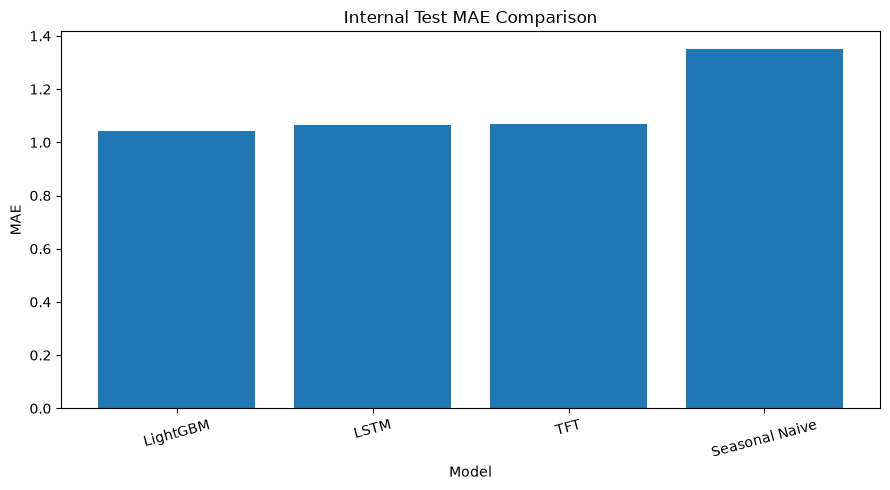

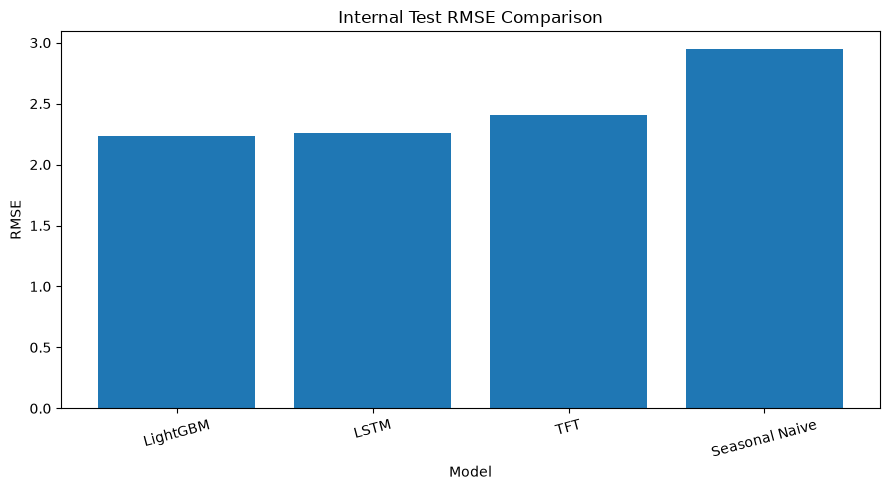

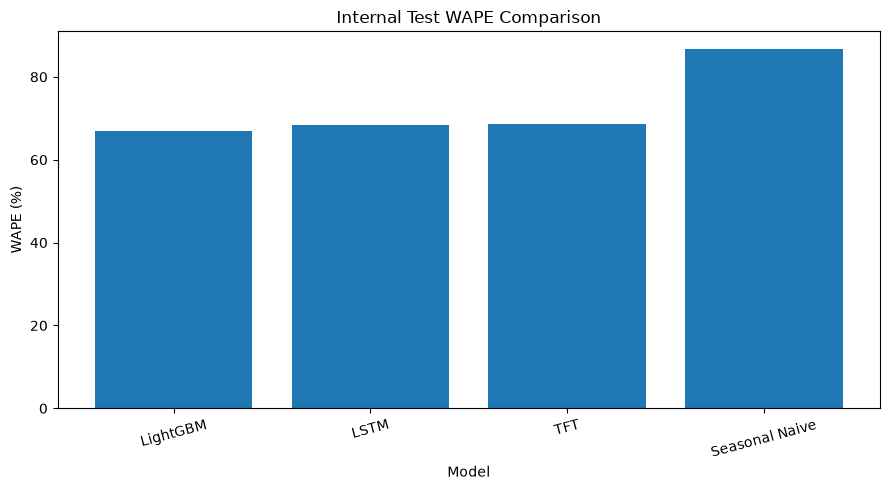

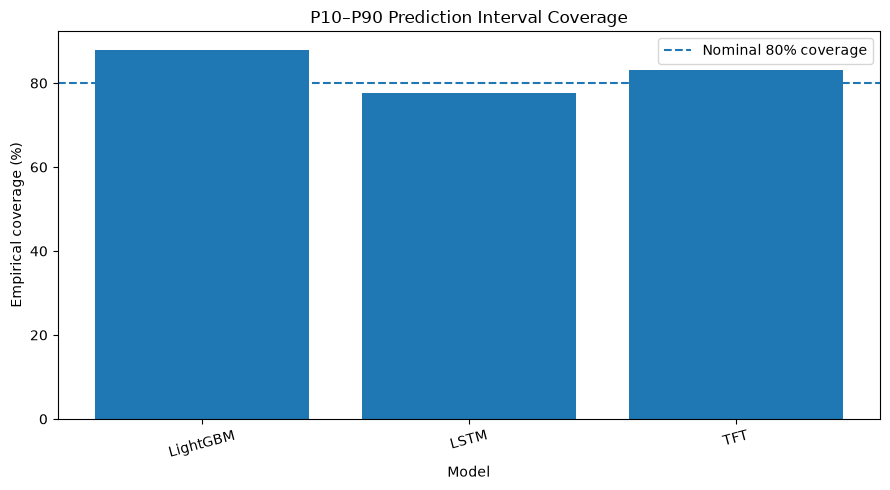

In [5]:
import matplotlib.pyplot as plt

# MAE comparison
plt.figure(figsize=(9, 5))

plt.bar(
    overall_comparison["Model"],
    overall_comparison["MAE"]
)

plt.title("Internal Test MAE Comparison")
plt.xlabel("Model")
plt.ylabel("MAE")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "internal_test_mae_comparison.png",
    dpi=300
)
plt.show()


# RMSE comparison
plt.figure(figsize=(9, 5))

plt.bar(
    overall_comparison["Model"],
    overall_comparison["RMSE"]
)

plt.title("Internal Test RMSE Comparison")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "internal_test_rmse_comparison.png",
    dpi=300
)
plt.show()


# WAPE comparison
plt.figure(figsize=(9, 5))

plt.bar(
    overall_comparison["Model"],
    overall_comparison["WAPE"] * 100
)

plt.title("Internal Test WAPE Comparison")
plt.xlabel("Model")
plt.ylabel("WAPE (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "internal_test_wape_comparison.png",
    dpi=300
)
plt.show()


# Probabilistic interval coverage
probabilistic = overall_comparison.dropna(
    subset=["interval_coverage"]
)

plt.figure(figsize=(9, 5))

plt.bar(
    probabilistic["Model"],
    probabilistic["interval_coverage"] * 100
)

plt.axhline(
    80,
    linestyle="--",
    label="Nominal 80% coverage"
)

plt.title("P10–P90 Prediction Interval Coverage")
plt.xlabel("Model")
plt.ylabel("Empirical coverage (%)")
plt.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(
    RESULT_DIR / "internal_test_interval_coverage.png",
    dpi=300
)
plt.show()

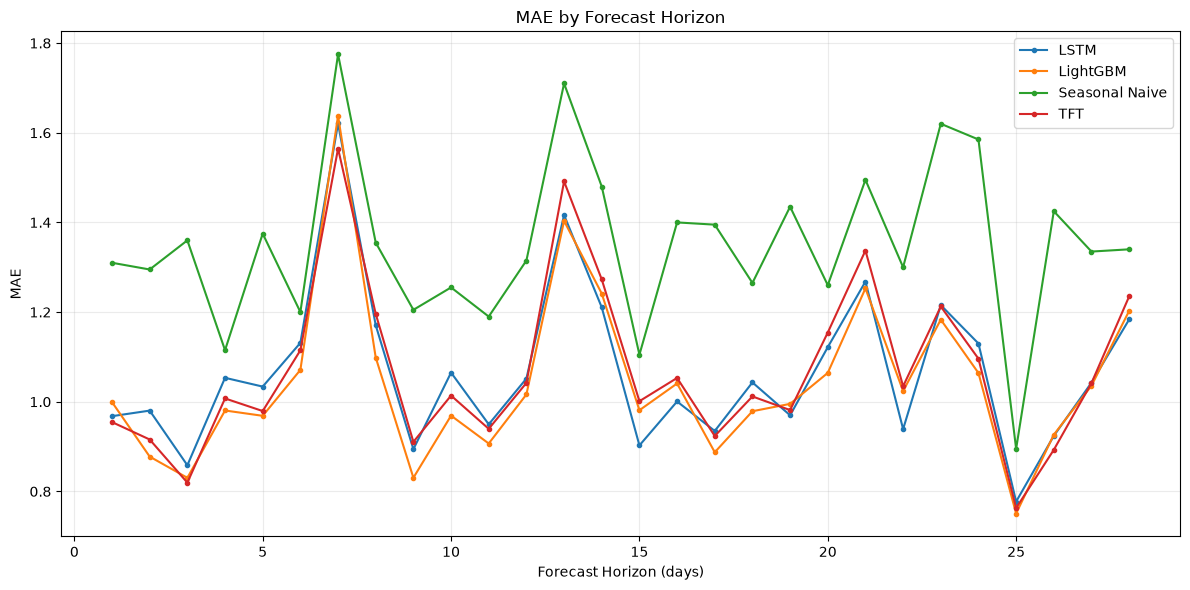

In [6]:
horizon_rows = []

for model_name, df in predictions.items():

    for horizon, group in df.groupby("horizon"):

        metrics = evaluate_predictions(group)

        horizon_rows.append({
            "Model": model_name,
            "Horizon": horizon,
            **metrics
        })

horizon_comparison = pd.DataFrame(horizon_rows)

horizon_comparison.to_csv(
    RESULT_DIR / "internal_test_horizon_comparison.csv",
    index=False
)

plt.figure(figsize=(12, 6))

for model_name, group in horizon_comparison.groupby("Model"):

    group = group.sort_values("Horizon")

    plt.plot(
        group["Horizon"],
        group["MAE"],
        marker="o",
        markersize=3,
        label=model_name
    )

plt.title("MAE by Forecast Horizon")
plt.xlabel("Forecast Horizon (days)")
plt.ylabel("MAE")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    RESULT_DIR / "internal_test_mae_by_horizon.png",
    dpi=300
)

plt.show()

In [7]:
comparison_summary = {
    "evaluation_period": {
        "training_cutoff": TEST_ORIGIN,
        "forecast_start": TEST_START,
        "forecast_end": TEST_END,
        "forecast_horizon": FORECAST_HORIZON
    },
    "series_count": len(SERIES_IDS),
    "observation_count": len(reference),
    "models": list(predictions.keys()),
    "best_model_by_mae": overall_comparison.iloc[0]["Model"],
    "best_model_by_rmse": overall_comparison.loc[
        overall_comparison["RMSE"].idxmin(), "Model"
    ],
    "best_model_by_wape": overall_comparison.loc[
        overall_comparison["WAPE"].idxmin(), "Model"
    ]
}

with open(
    RESULT_DIR / "internal_test_comparison_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(comparison_summary, f, indent=4)

print(json.dumps(comparison_summary, indent=4))
print("\nAll comparison artifacts saved to:", RESULT_DIR)

NameError: name 'SERIES_IDS' is not defined

## Model Evaluation Conclusion

The four forecasting models were evaluated on the same 200 product-store time series over the 28-day internal-test period (d_1886–d_1913), representing 5,600 observations per model.

LightGBM achieved the strongest overall point-forecast performance, recording an MAE of 1.0435, RMSE of 2.2380 and WAPE of 66.99%. It outperformed LSTM and TFT, although the differences between the three machine-learning models were relatively small. Both LSTM and TFT also substantially outperformed the Seasonal Naive benchmark, demonstrating the value of incorporating additional historical and calendar information.

Among the probabilistic models, LightGBM achieved the lowest P50 and P90 pinball losses, while LSTM achieved the lowest P10 pinball loss. TFT recorded no observed P10–P90 quantile crossings, although this alone does not establish superior probabilistic calibration.

An important limitation was observed in quantile calibration. The empirical P10 coverage was substantially higher than its nominal 10% level across all three probabilistic models. This suggests that the lower-quantile forecasts require further calibration analysis. The results should therefore be interpreted alongside interval coverage, interval width and demand-specific diagnostics rather than relying exclusively on point-forecast metrics.

Overall, the results suggest that machine learning models can capture retail demand patterns more effectively than Seasonal Naive. However, the WAPE of 66.99% indicates that forecast errors remain relatively high.

Key takeaway: LightGBM is currently the strongest model among the four tested, but further improvements in forecast accuracy and probabilistic calibration are needed before considering it reliable for operational inventory decisions.

- **LSTM and TFT have lower performance is suspectedly due to low num_trials during Optuna hyperparameter tuning, as both have high training time, hence num_trials is limited to very low.**

### Understand model performance across forecast horizons, demand patterns, and prediction intervals
- Using test set

In [15]:
from pathlib import Path

PROJECT_ROOT = Path(
    r"C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence"
)

PREDICTION_DIR = PROJECT_ROOT / "data" / "processed" / "model_comparison" / "predictions"
DAILY_DATA_PATH = PROJECT_ROOT / "data" / "processed" / "daily_model_features.parquet"

RESULTS_DIR = PROJECT_ROOT / "results" / "model_comparison"
TEST_ORIGIN = 1885
TEST_START = 1886
TEST_END = 1913
FORECAST_HORIZON = 28
EXPECTED_SERIES = 200
EXPECTED_OBSERVATIONS = EXPECTED_SERIES * FORECAST_HORIZON

print("Project root:", PROJECT_ROOT)
print("Prediction directory exists:", PREDICTION_DIR.exists())
print("Daily data exists:", DAILY_DATA_PATH.exists())
print("Results directory:", RESULTS_DIR)

Project root: C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence
Prediction directory exists: True
Daily data exists: True
Results directory: C:\Users\cjc72\Desktop\SalesForecasting\AI-Retail-Demand-Intelligence\results\model_comparison


In [16]:
prediction_files = sorted(
    list(PREDICTION_DIR.glob("*.parquet")) +
    list(PREDICTION_DIR.glob("*.csv"))
)

if not prediction_files:
    raise FileNotFoundError(
        f"No CSV or Parquet prediction files found in: {PREDICTION_DIR}"
    )

for file_path in prediction_files:
    print(f"\nFile: {file_path.name}")

    if file_path.suffix == ".parquet":
        temp_df = pd.read_parquet(file_path)
    else:
        temp_df = pd.read_csv(file_path)

    print("Shape:", temp_df.shape)
    print("Columns:", temp_df.columns.tolist())
    display(temp_df.head(3))


File: lightgbm_internal_test.parquet
Shape: (5600, 8)
Columns: ['id', 'origin_day_num', 'target_day_num', 'horizon', 'y_true', 'p10', 'p50', 'p90']


,id,origin_day_num,target_day_num,horizon,y_true,p10,p50,p90
0,FOODS_3_339_CA_1_evaluation,1885,1886,1,7,0.655159,4.593938,11.395696
1,FOODS_3_339_CA_1_evaluation,1885,1887,2,10,0.655159,4.239145,10.717981
2,FOODS_3_339_CA_1_evaluation,1885,1888,3,8,0.655159,4.239145,10.724299



File: lstm_internal_test.parquet
Shape: (5600, 8)
Columns: ['id', 'origin_day_num', 'target_day_num', 'horizon', 'y_true', 'p10', 'p50', 'p90']


,id,origin_day_num,target_day_num,horizon,y_true,p10,p50,p90
0,FOODS_1_020_WI_2_evaluation,1885,1886,1,1.0,-0.014404,1.859944,4.983910
1,FOODS_1_020_WI_2_evaluation,1885,1887,2,3.0,-0.006185,1.904678,4.923421
2,FOODS_1_020_WI_2_evaluation,1885,1888,3,1.0,0.002485,1.873467,4.805232



File: seasonal_naive_internal_test.parquet
Shape: (5600, 8)
Columns: ['id', 'origin_day_num', 'target_day_num', 'horizon', 'y_true', 'p10', 'p50', 'p90']


,id,origin_day_num,target_day_num,horizon,y_true,p10,p50,p90
0,FOODS_1_020_WI_2_evaluation,1885,1886,1,1.0,NaN,3.0,NaN
1,FOODS_1_020_WI_2_evaluation,1885,1887,2,3.0,NaN,1.0,NaN
2,FOODS_1_020_WI_2_evaluation,1885,1888,3,1.0,NaN,0.0,NaN



File: tft_internal_test.parquet
Shape: (5600, 8)
Columns: ['id', 'origin_day_num', 'target_day_num', 'horizon', 'y_true', 'p10', 'p50', 'p90']


,id,origin_day_num,target_day_num,horizon,y_true,p10,p50,p90
0,FOODS_1_020_WI_2_evaluation,1885,1886,1,1.0,-0.003247,1.142755,3.163360
1,FOODS_1_020_WI_2_evaluation,1885,1887,2,3.0,-0.004319,1.205440,3.192178
2,FOODS_1_020_WI_2_evaluation,1885,1888,3,1.0,0.002226,1.307349,3.373499


In [18]:
MODEL_FILE_KEYWORDS = {
    "Seasonal Naive": ["seasonal_naive", "naive"],
    "LightGBM": ["lightgbm", "lgbm"],
    "LSTM": ["lstm"],
    "TFT": ["tft", "temporal_fusion"]
}

def find_model_file(model_name, keywords, files):
    matches = [
        file_path
        for file_path in files
        if any(keyword in file_path.stem.lower() for keyword in keywords)
    ]

    if len(matches) != 1:
        raise ValueError(
            f"{model_name}: expected exactly one matching file, "
            f"but found {len(matches)}: {[p.name for p in matches]}. "
            "Update MODEL_FILE_KEYWORDS or specify the file manually."
        )

    return matches[0]


PREDICTION_FILES = {
    model: find_model_file(model, keywords, prediction_files)
    for model, keywords in MODEL_FILE_KEYWORDS.items()
}

for model, file_path in PREDICTION_FILES.items():
    print(f"{model}: {file_path.name}")

Seasonal Naive: seasonal_naive_internal_test.parquet
LightGBM: lightgbm_internal_test.parquet
LSTM: lstm_internal_test.parquet
TFT: tft_internal_test.parquet


In [20]:
import numpy as np
import re

COLUMN_ALIASES = {
    "id": ["id", "series_id"],
    "target_day_num": [
        "target_day_num", "day_num", "target_day", "d"
    ],
    "horizon": ["horizon", "forecast_horizon"],
    "y_true": [
        "y_true", "actual", "actual_sales", "sales", "target_sales"
    ],
    "p10": [
        "p10", "pred_p10", "prediction_p10", "y_pred_p10", "forecast_p10"
    ],
    "p50": [
        "p50", "pred_p50", "prediction_p50", "y_pred_p50",
        "forecast_p50", "prediction", "y_pred"
    ],
    "p90": [
        "p90", "pred_p90", "prediction_p90", "y_pred_p90", "forecast_p90"
    ]
}


def find_column(df, candidates, required=True):
    lookup = {str(column).lower(): column for column in df.columns}

    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]

    if required:
        raise KeyError(
            f"Could not find any of these columns: {candidates}. "
            f"Available columns: {df.columns.tolist()}"
        )

    return None


def load_prediction_file(file_path, model_name):
    if file_path.suffix.lower() == ".parquet":
        df = pd.read_parquet(file_path)
    else:
        df = pd.read_csv(file_path)

    output = pd.DataFrame()
    output["id"] = df[find_column(df, COLUMN_ALIASES["id"])].astype(str)

    actual_col = find_column(df, COLUMN_ALIASES["y_true"])
    output["y_true"] = pd.to_numeric(df[actual_col], errors="coerce")

    target_col = find_column(
        df, COLUMN_ALIASES["target_day_num"], required=False
    )

    if target_col is not None:
        raw_target = df[target_col]

        if pd.api.types.is_numeric_dtype(raw_target):
            output["target_day_num"] = pd.to_numeric(
                raw_target, errors="coerce"
            )
        else:
            extracted = raw_target.astype(str).str.extract(r"(\d+)$")[0]
            output["target_day_num"] = pd.to_numeric(
                extracted, errors="coerce"
            )
    else:
        horizon_col = find_column(
            df, COLUMN_ALIASES["horizon"], required=False
        )

        if horizon_col is None:
            raise KeyError(
                f"{file_path.name} needs a target-day or horizon column."
            )

        output["target_day_num"] = (
            TEST_ORIGIN
            + pd.to_numeric(df[horizon_col], errors="coerce")
        )

    for quantile in ["p10", "p50", "p90"]:
        source_col = find_column(
            df, COLUMN_ALIASES[quantile], required=False
        )

        if source_col is None:
            output[quantile] = np.nan
        else:
            output[quantile] = pd.to_numeric(
                df[source_col], errors="coerce"
            )

    output["model"] = model_name
    output["target_day_num"] = pd.to_numeric(
        output["target_day_num"], errors="coerce"
    )

    output["horizon"] = (
        output["target_day_num"] - TEST_ORIGIN
    ).astype("Int64")

    return output


prediction_frames = []

for model_name, file_path in PREDICTION_FILES.items():
    model_df = load_prediction_file(file_path, model_name)
    prediction_frames.append(model_df)

predictions = pd.concat(prediction_frames, ignore_index=True)

print("Combined prediction shape:", predictions.shape)
print("\nRows per model:")
print(predictions.groupby("model").size())

print("\nPrediction sample:")
print(predictions.head())

Combined prediction shape: (22400, 8)

Rows per model:
model
LSTM              5600
LightGBM          5600
Seasonal Naive    5600
TFT               5600
dtype: int64

Prediction sample:
                            id  y_true  target_day_num  p10  p50  p90  \
0  FOODS_1_020_WI_2_evaluation     1.0            1886  NaN  3.0  NaN   
1  FOODS_1_020_WI_2_evaluation     3.0            1887  NaN  1.0  NaN   
2  FOODS_1_020_WI_2_evaluation     1.0            1888  NaN  0.0  NaN   
3  FOODS_1_020_WI_2_evaluation     1.0            1889  NaN  0.0  NaN   
4  FOODS_1_020_WI_2_evaluation     1.0            1890  NaN  1.0  NaN   

            model  horizon  
0  Seasonal Naive        1  
1  Seasonal Naive        2  
2  Seasonal Naive        3  
3  Seasonal Naive        4  
4  Seasonal Naive        5  


In [21]:
expected_days = set(range(TEST_START, TEST_END + 1))

for model_name, model_df in predictions.groupby("model"):
    assert model_df["id"].nunique() == EXPECTED_SERIES, (
        f"{model_name}: unexpected number of series."
    )

    assert len(model_df) == EXPECTED_OBSERVATIONS, (
        f"{model_name}: expected {EXPECTED_OBSERVATIONS} rows, "
        f"received {len(model_df)}."
    )

    assert set(model_df["target_day_num"].dropna().astype(int)) == expected_days, (
        f"{model_name}: unexpected target days."
    )

    assert not model_df.duplicated(["id", "target_day_num"]).any(), (
        f"{model_name}: duplicate series-target-day combinations."
    )

    assert model_df["y_true"].notna().all(), (
        f"{model_name}: missing actual values."
    )

    assert (model_df["y_true"] >= 0).all(), (
        f"{model_name}: negative actual sales found."
    )

print("Basic prediction validation passed.")

# Verify that all models use exactly the same series-day keys and actuals.
reference_model = "Seasonal Naive"

reference = (
    predictions[predictions["model"] == reference_model]
    [["id", "target_day_num", "y_true"]]
    .sort_values(["id", "target_day_num"])
    .reset_index(drop=True)
)

for model_name in predictions["model"].unique():
    current = (
        predictions[predictions["model"] == model_name]
        [["id", "target_day_num", "y_true"]]
        .sort_values(["id", "target_day_num"])
        .reset_index(drop=True)
    )

    assert reference[["id", "target_day_num"]].equals(
        current[["id", "target_day_num"]]
    ), f"{model_name}: prediction keys do not match."

    assert np.allclose(
        reference["y_true"],
        current["y_true"],
        equal_nan=False
    ), f"{model_name}: actual values do not match."

print("Cross-model alignment and actual-value checks passed.")

Basic prediction validation passed.
Cross-model alignment and actual-value checks passed.


In [ ]:
def calculate_pinball_loss(y_true, y_pred, quantile):
    error = y_true - y_pred
    return np.mean(
        np.maximum(quantile * error, (quantile - 1) * error)
    )


def calculate_metrics(df):
    y = df["y_true"].to_numpy(dtype=float)
    p50 = df["p50"].to_numpy(dtype=float)

    result = {
        "observations": len(df),
        "MAE": np.mean(np.abs(y - p50)),
        "RMSE": np.sqrt(np.mean((y - p50) ** 2)),
        "WAPE": (
            np.sum(np.abs(y - p50)) / np.sum(np.abs(y))
            if np.sum(np.abs(y)) > 0 else np.nan
        )
    }

    if df[["p10", "p50", "p90"]].notna().all(axis=None):
        p10 = df["p10"].to_numpy(dtype=float)
        p90 = df["p90"].to_numpy(dtype=float)

        result.update({
            "P10_pinball": calculate_pinball_loss(y, p10, 0.10),
            "P50_pinball": calculate_pinball_loss(y, p50, 0.50),
            "P90_pinball": calculate_pinball_loss(y, p90, 0.90),
            "P10_coverage": np.mean(y <= p10),
            "P90_coverage": np.mean(y <= p90),
            "interval_coverage": np.mean((y >= p10) & (y <= p90)),
            "interval_width": np.mean(p90 - p10),
            "quantile_crossing_rate": np.mean(
                (p10 > df["p50"].to_numpy(dtype=float))
                | (df["p50"].to_numpy(dtype=float) > p90)
            )
        })

    return result


def build_group_metrics(df, group_columns, metric_function):
    results = []

    for group_values, group_df in df.groupby(
        group_columns, sort=False, dropna=False
    ):
        if not isinstance(group_values, tuple):
            group_values = (group_values,)

        row = dict(zip(group_columns, group_values))
        row.update(metric_function(group_df))
        results.append(row)

    return pd.DataFrame(results)


overall_metrics = build_group_metrics(
    predictions,
    ["model"],
    calculate_metrics
)

overall_metrics["WAPE_percent"] = overall_metrics["WAPE"] * 100
overall_metrics["P10_coverage_percent"] = (
    overall_metrics["P10_coverage"] * 100
)
overall_metrics["P90_coverage_percent"] = (
    overall_metrics["P90_coverage"] * 100
)
overall_metrics["interval_coverage_percent"] = (
    overall_metrics["interval_coverage"] * 100
)
overall_metrics["quantile_crossing_percent"] = (
    overall_metrics["quantile_crossing_rate"] * 100
)

print(overall_metrics.round(4).to_string(index=False))

overall_metrics.to_csv(
    RESULTS_DIR / "overall_model_metrics.csv",
    index=False
)

         model  observations    MAE   RMSE   WAPE  P10_pinball  P50_pinball  P90_pinball  P10_coverage  P90_coverage  interval_coverage  interval_width  quantile_crossing_rate  WAPE_percent  P10_coverage_percent  P90_coverage_percent  interval_coverage_percent  quantile_crossing_percent
Seasonal Naive          5600 1.3498 2.9458 0.8666          NaN          NaN          NaN           NaN           NaN                NaN             NaN                     NaN       86.6560                   NaN                   NaN                        NaN                        NaN
      LightGBM          5600 1.0435 2.2380 0.6699       0.1542       0.5218       0.3406        0.5429        0.8927             0.8793          3.3516                  0.0191       66.9920               54.2857               89.2679                    87.9286                     1.9107
          LSTM          5600 1.0663 2.2579 0.6845       0.1488       0.5331       0.3561        0.1343        0.9100             0.7761 

In [ ]:
horizon_metrics = (
    predictions
    .groupby(["model", "horizon"], sort=False)
    .apply(calculate_metrics)
    .reset_index()
)

horizon_metrics = build_group_metrics(
    predictions,
    ["model", "horizon"],
    calculate_metrics
)

horizon_metrics["WAPE_percent"] = horizon_metrics["WAPE"] * 100

horizon_metrics.to_csv(
    RESULTS_DIR / "horizon_level_metrics.csv",
    index=False
)

#print(horizon_metrics.round(4).to_string(index=False))

         model  horizon  observations    MAE   RMSE   WAPE  P10_pinball  P50_pinball  P90_pinball  P10_coverage  P90_coverage  interval_coverage  interval_width  quantile_crossing_rate  WAPE_percent
Seasonal Naive        1           200 1.3100 3.3377 0.9034          NaN          NaN          NaN           NaN           NaN                NaN             NaN                     NaN       90.3448
Seasonal Naive        2           200 1.2950 2.7937 1.0571          NaN          NaN          NaN           NaN           NaN                NaN             NaN                     NaN      105.7143
Seasonal Naive        3           200 1.3600 3.4351 1.1193          NaN          NaN          NaN           NaN           NaN                NaN             NaN                     NaN      111.9342
Seasonal Naive        4           200 1.1150 2.2793 0.8447          NaN          NaN          NaN           NaN           NaN                NaN             NaN                     NaN       84.4697
Seaso

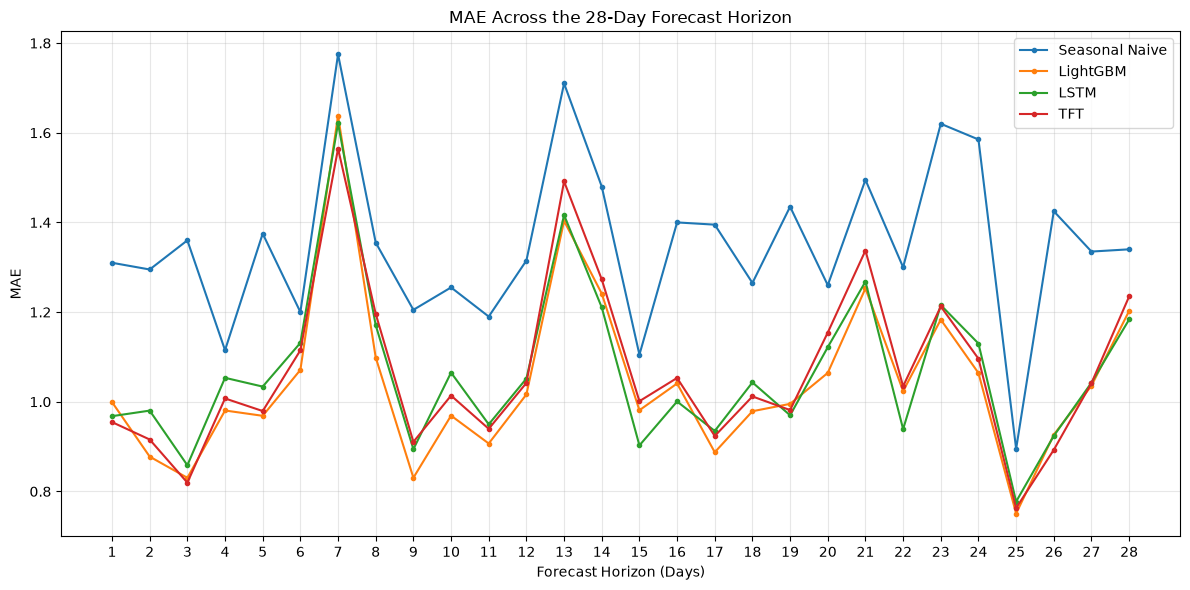

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for model_name in predictions["model"].unique():
    model_data = horizon_metrics[
        horizon_metrics["model"] == model_name
    ].sort_values("horizon")

    plt.plot(
        model_data["horizon"],
        model_data["MAE"],
        marker="o",
        markersize=3,
        label=model_name
    )

plt.xlabel("Forecast Horizon (Days)")
plt.ylabel("MAE")
plt.title("MAE Across the 28-Day Forecast Horizon")
plt.xticks(range(1, FORECAST_HORIZON + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "mae_by_forecast_horizon.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

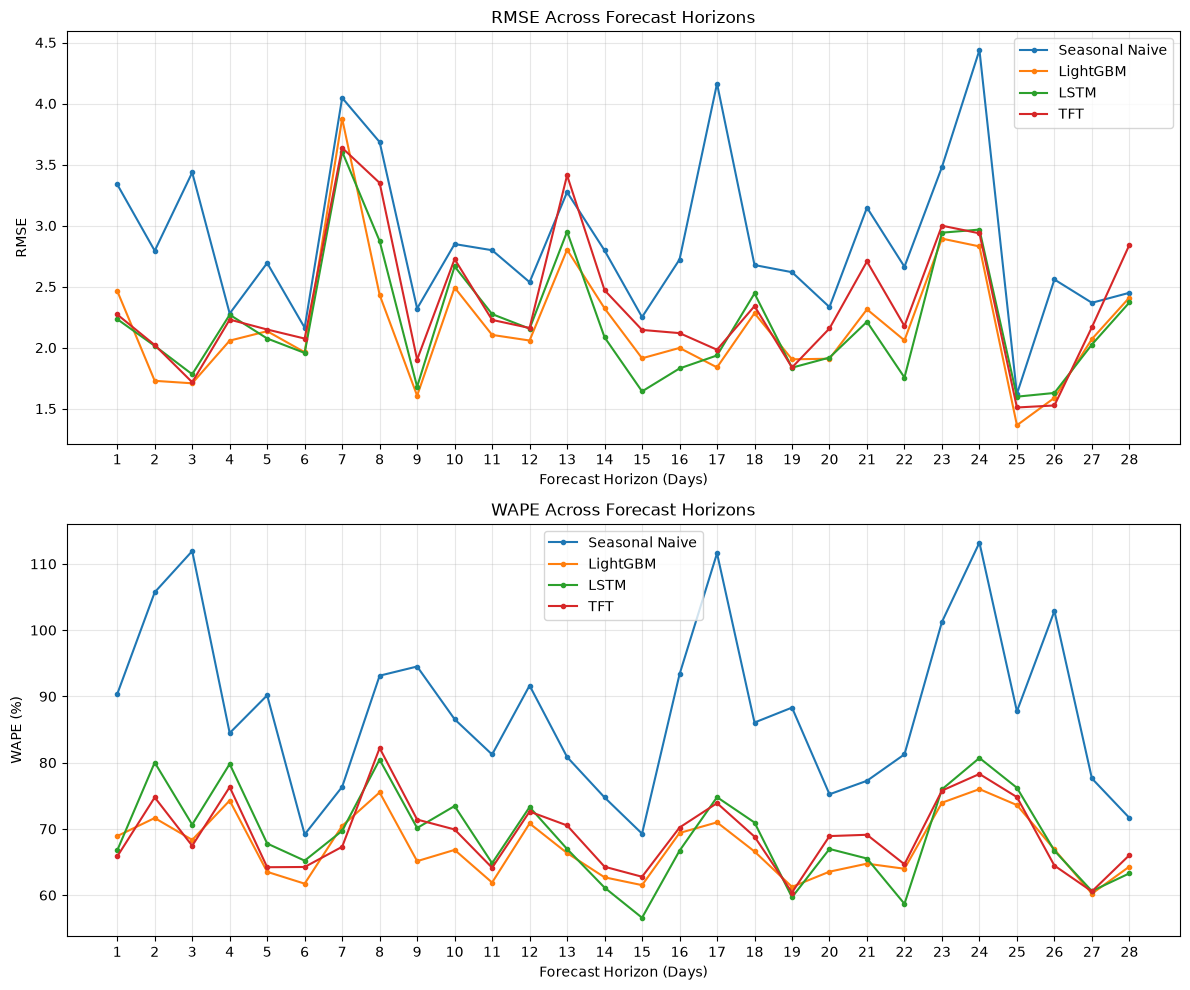

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

for model_name in predictions["model"].unique():
    model_data = horizon_metrics[
        horizon_metrics["model"] == model_name
    ].sort_values("horizon")

    axes[0].plot(
        model_data["horizon"],
        model_data["RMSE"],
        marker="o",
        markersize=3,
        label=model_name
    )

    axes[1].plot(
        model_data["horizon"],
        model_data["WAPE_percent"],
        marker="o",
        markersize=3,
        label=model_name
    )

axes[0].set_title("RMSE Across Forecast Horizons")
axes[0].set_xlabel("Forecast Horizon (Days)")
axes[0].set_ylabel("RMSE")
axes[0].set_xticks(range(1, FORECAST_HORIZON + 1))
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].set_title("WAPE Across Forecast Horizons")
axes[1].set_xlabel("Forecast Horizon (Days)")
axes[1].set_ylabel("WAPE (%)")
axes[1].set_xticks(range(1, FORECAST_HORIZON + 1))
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "rmse_wape_by_forecast_horizon.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
import duckdb

selected_ids = (
    predictions[["id"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

con = duckdb.connect()
con.register("selected_ids", selected_ids)

demand_statistics = con.execute(
    """
    WITH panel AS (
        SELECT
            CAST(d.id AS VARCHAR) AS id,
            TRY_CAST(SUBSTRING(d.d, 3) AS INTEGER) AS day_num,
            CAST(d.sales AS DOUBLE) AS sales
        FROM read_parquet(?) AS d
        INNER JOIN selected_ids AS s
            ON CAST(d.id AS VARCHAR) = s.id
        WHERE TRY_CAST(SUBSTRING(d.d, 3) AS INTEGER) <= ?
    ),

    series_stats AS (
        SELECT
            id,
            COUNT(*) AS observed_periods,
            COUNT(*) FILTER (WHERE sales > 0) AS nonzero_periods,
            AVG(sales) FILTER (WHERE sales > 0) AS mean_positive_demand,
            VAR_POP(sales) FILTER (WHERE sales > 0) AS variance_positive_demand
        FROM panel
        GROUP BY id
    )

    SELECT
        id,
        observed_periods,
        nonzero_periods,
        CASE
            WHEN nonzero_periods > 0
            THEN observed_periods * 1.0 / nonzero_periods
            ELSE NULL
        END AS adi,
        CASE
            WHEN nonzero_periods > 0
                 AND mean_positive_demand > 0
            THEN variance_positive_demand
                 / POWER(mean_positive_demand, 2)
            ELSE NULL
        END AS cv2
    FROM series_stats
    """,
    [str(DAILY_DATA_PATH), TEST_ORIGIN]
).df()

con.close()

def classify_demand(row):
    if row["nonzero_periods"] == 0:
        return "No Demand"

    if row["adi"] <= 1.32:
        if row["cv2"] <= 0.49:
            return "Smooth"
        return "Erratic"

    if row["cv2"] <= 0.49:
        return "Intermittent"

    return "Lumpy"


demand_statistics["demand_class"] = demand_statistics.apply(
    classify_demand,
    axis=1
)

assert demand_statistics["id"].nunique() == EXPECTED_SERIES
assert demand_statistics["demand_class"].notna().all()

print("Demand classification counts:")
print(
    demand_statistics["demand_class"]
    .value_counts()
    .to_string()
)

demand_statistics.to_csv(
    RESULTS_DIR / "demand_pattern_classification.csv",
    index=False
)

Demand classification counts:
demand_class
Intermittent    150
Lumpy            37
Smooth           10
Erratic           3


In [31]:
predictions = predictions.merge(
    demand_statistics[["id", "adi", "cv2", "demand_class"]],
    on="id",
    how="left",
    validate="many_to_one"
)

assert predictions["demand_class"].notna().all()

print(
    predictions[["id", "demand_class"]]
    .drop_duplicates()["demand_class"]
    .value_counts()
)

print("\nPrediction rows by demand category:")
print(
    predictions.groupby("demand_class")
    .size()
    .sort_values(ascending=False)
)

demand_class
Intermittent    150
Lumpy            37
Smooth           10
Erratic           3
Name: count, dtype: int64

Prediction rows by demand category:
demand_class
Intermittent    16800
Lumpy            4144
Smooth           1120
Erratic           336
dtype: int64


In [33]:
demand_class_metrics = (
    predictions
    .groupby(["model", "demand_class"], sort=False)
    .apply(calculate_metrics)
    .reset_index()
)

demand_class_metrics = build_group_metrics(
    predictions,
    ["model", "demand_class"],
    calculate_metrics
)

demand_class_metrics["WAPE_percent"] = (
    demand_class_metrics["WAPE"] * 100
)

demand_class_metrics.to_csv(
    RESULTS_DIR / "performance_by_demand_class.csv",
    index=False
)

print(demand_class_metrics.round(4).to_string(index=False))

         model demand_class  observations    MAE   RMSE   WAPE  P10_pinball  P50_pinball  P90_pinball  P10_coverage  P90_coverage  interval_coverage  interval_width  quantile_crossing_rate  WAPE_percent
Seasonal Naive Intermittent          4200 0.8814 1.8005 0.9711          NaN          NaN          NaN           NaN           NaN                NaN             NaN                     NaN       97.1144
Seasonal Naive        Lumpy          1036 2.2104 3.9488 0.9662          NaN          NaN          NaN           NaN           NaN                NaN             NaN                     NaN       96.6245
Seasonal Naive       Smooth           280 4.4214 7.7006 0.5769          NaN          NaN          NaN           NaN           NaN                NaN             NaN                     NaN       57.6887
Seasonal Naive      Erratic            84 3.9167 5.1420 0.8329          NaN          NaN          NaN           NaN           NaN                NaN             NaN                     NaN

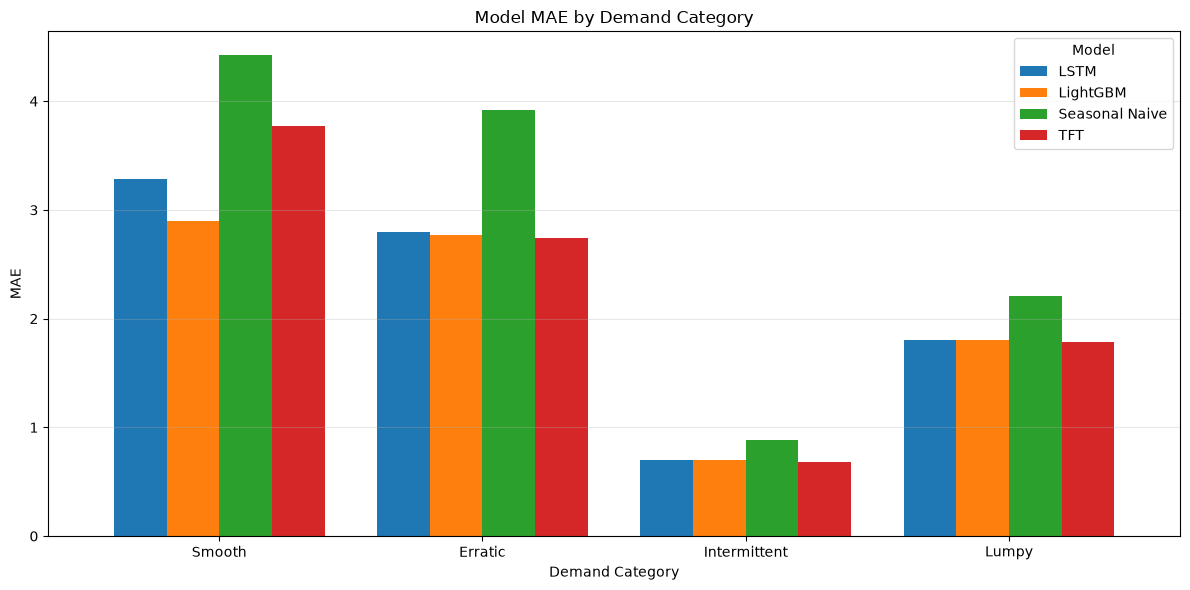

In [34]:
demand_plot_data = demand_class_metrics.pivot(
    index="demand_class",
    columns="model",
    values="MAE"
)

demand_order = [
    category for category in
    ["Smooth", "Erratic", "Intermittent", "Lumpy", "No Demand"]
    if category in demand_plot_data.index
]

demand_plot_data = demand_plot_data.reindex(demand_order)

ax = demand_plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Model MAE by Demand Category")
ax.set_xlabel("Demand Category")
ax.set_ylabel("MAE")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Model")

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "mae_by_demand_class.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
probabilistic_predictions = predictions.dropna(
    subset=["p10", "p50", "p90"]
).copy()

if probabilistic_predictions.empty:
    raise ValueError(
        "No complete P10/P50/P90 predictions were found."
    )


def calculate_calibration(df):
    y = df["y_true"].to_numpy(dtype=float)
    p10 = df["p10"].to_numpy(dtype=float)
    p90 = df["p90"].to_numpy(dtype=float)
    p50 = df["p50"].to_numpy(dtype=float)

    return {
        "observations": len(df),
        "P10_coverage": np.mean(y <= p10),
        "P90_coverage": np.mean(y <= p90),
        "interval_coverage": np.mean((y >= p10) & (y <= p90)),
        "mean_interval_width": np.mean(p90 - p10),
        "P10_strict_coverage": np.mean(y < p10),
        "P90_strict_coverage": np.mean(y < p90),
        "quantile_crossing_rate": np.mean(
            (p10 > p50) | (p50 > p90)
        )
    }


calibration_by_model = build_group_metrics(
    probabilistic_predictions,
    ["model"],
    calculate_calibration
)

calibration_by_model.to_csv(
    RESULTS_DIR / "probabilistic_calibration_by_model.csv",
    index=False
)

print(calibration_by_model.round(4).to_string(index=False))

   model  observations  P10_coverage  P90_coverage  interval_coverage  mean_interval_width  P10_strict_coverage  P90_strict_coverage  quantile_crossing_rate
LightGBM          5600        0.5429        0.8927             0.8793               3.3516               0.0134               0.8927                  0.0191
    LSTM          5600        0.1343        0.9100             0.7761               3.4003               0.1343               0.9100                  0.0559
     TFT          5600        0.0546        0.8852             0.8305               3.0526               0.0546               0.8852                  0.0005


In [36]:
calibration_by_demand_class = (
    probabilistic_predictions
    .groupby(["model", "demand_class"], sort=False)
    .apply(calculate_calibration)
    .reset_index()
)

calibration_by_demand_class.to_csv(
    RESULT_DIR / "probabilistic_calibration_by_demand_class.csv",
    index=False
)

print(
    calibration_by_demand_class
    .round(4)
    .to_string(index=False)
)

   model demand_class                                                                                                                                                                                                                                                                                                                           0
LightGBM        Lumpy    {'observations': 1036, 'P10_coverage': 0.4411196911196911, 'P90_coverage': 0.8812741312741312, 'interval_coverage': 0.8445945945945946, 'mean_interval_width': 5.223765487321671, 'P10_strict_coverage': 0.03667953667953668, 'P90_strict_coverage': 0.8812741312741312, 'quantile_crossing_rate': 0.019305019305019305}
LightGBM      Erratic                      {'observations': 84, 'P10_coverage': 0.03571428571428571, 'P90_coverage': 0.8571428571428571, 'interval_coverage': 0.8214285714285714, 'mean_interval_width': 8.933191386684955, 'P10_strict_coverage': 0.03571428571428571, 'P90_strict_coverage': 0.8571428571428571, 'quantile_crossin

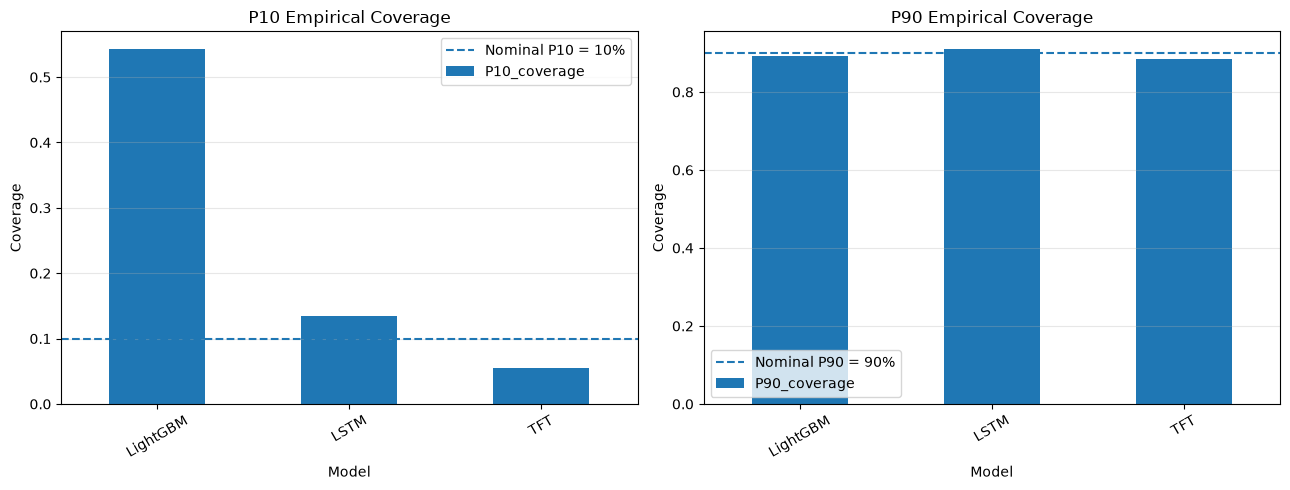

In [38]:
coverage_plot_data = calibration_by_model.set_index("model")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

coverage_plot_data["P10_coverage"].plot(
    kind="bar",
    ax=axes[0]
)

axes[0].axhline(
    y=0.10,
    linestyle="--",
    label="Nominal P10 = 10%"
)

axes[0].set_title("P10 Empirical Coverage")
axes[0].set_ylabel("Coverage")
axes[0].set_xlabel("Model")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

coverage_plot_data["P90_coverage"].plot(
    kind="bar",
    ax=axes[1]
)

axes[1].axhline(
    y=0.90,
    linestyle="--",
    label="Nominal P90 = 90%"
)

axes[1].set_title("P90 Empirical Coverage")
axes[1].set_ylabel("Coverage")
axes[1].set_xlabel("Model")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "quantile_coverage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

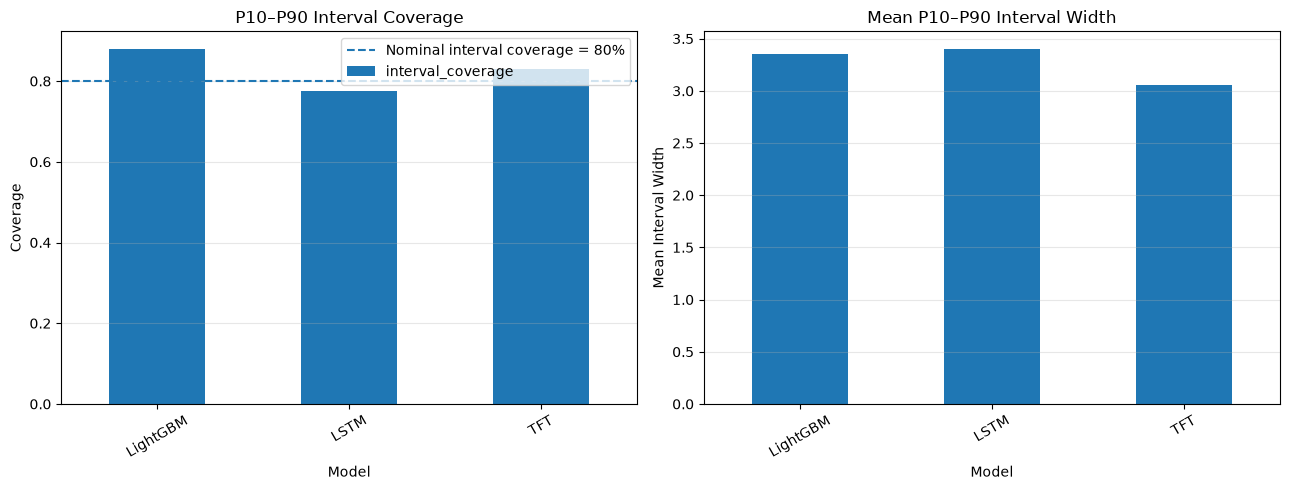

In [40]:
interval_plot_data = calibration_by_model.set_index("model")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

interval_plot_data["interval_coverage"].plot(
    kind="bar",
    ax=axes[0]
)

axes[0].axhline(
    y=0.80,
    linestyle="--",
    label="Nominal interval coverage = 80%"
)

axes[0].set_title("P10–P90 Interval Coverage")
axes[0].set_ylabel("Coverage")
axes[0].set_xlabel("Model")
axes[0].tick_params(axis="x", rotation=30)
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

interval_plot_data["mean_interval_width"].plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Mean P10–P90 Interval Width")
axes[1].set_ylabel("Mean Interval Width")
axes[1].set_xlabel("Model")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULT_DIR / "interval_coverage_and_width.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
crossing_summary = (
    probabilistic_predictions
    .groupby("model")
    .apply(
        lambda df: pd.Series({
            "observations": len(df),
            "P10_above_P50": np.mean(df["p10"] > df["p50"]),
            "P50_above_P90": np.mean(df["p50"] > df["p90"]),
            "any_quantile_crossing": np.mean(
                (df["p10"] > df["p50"])
                | (df["p50"] > df["p90"])
            )
        })
    )
    .reset_index()
)

crossing_summary.to_csv(
    RESULT_DIR / "quantile_crossing_summary.csv",
    index=False
)

print(crossing_summary.round(4).to_string(index=False))

   model  observations  P10_above_P50  P50_above_P90  any_quantile_crossing
    LSTM        5600.0         0.0559         0.0004                 0.0559
LightGBM        5600.0         0.0143         0.0048                 0.0191
     TFT        5600.0         0.0005         0.0000                 0.0005


In [45]:
# Save predictions with demand classifications.
predictions.to_parquet(
    RESULT_DIR / "internal_test_predictions_with_demand_class.parquet",
    index=False
)

predictions.to_csv(
    RESULT_DIR / "internal_test_predictions_with_demand_class.csv",
    index=False
)

# Save all metric tables.
overall_metrics.to_csv(
    RESULT_DIR / "overall_model_metrics.csv",
    index=False
)

horizon_metrics.to_csv(
    RESULT_DIR / "horizon_level_metrics.csv",
    index=False
)

demand_class_metrics.to_csv(
    RESULT_DIR / "performance_by_demand_class.csv",
    index=False
)

calibration_by_model.to_csv(
    RESULT_DIR / "probabilistic_calibration_by_model.csv",
    index=False
)

calibration_by_demand_class.to_csv(
    RESULT_DIR / "probabilistic_calibration_by_demand_class.csv",
    index=False
)

crossing_summary.to_csv(
    RESULT_DIR / "quantile_crossing_summary.csv",
    index=False
)

# Calculate improvement over Seasonal Naive.
naive_metrics = overall_metrics[
    overall_metrics["model"] == "Seasonal Naive"
].iloc[0]

comparison_summary = overall_metrics[
    ["model", "MAE", "RMSE", "WAPE", "WAPE_percent"]
].copy()

comparison_summary["MAE_improvement_vs_naive_percent"] = (
    (naive_metrics["MAE"] - comparison_summary["MAE"])
    / naive_metrics["MAE"] * 100
)

comparison_summary["RMSE_improvement_vs_naive_percent"] = (
    (naive_metrics["RMSE"] - comparison_summary["RMSE"])
    / naive_metrics["RMSE"] * 100
)

comparison_summary["WAPE_improvement_vs_naive_percent"] = (
    (naive_metrics["WAPE"] - comparison_summary["WAPE"])
    / naive_metrics["WAPE"] * 100
)

comparison_summary.to_csv(
    RESULT_DIR / "model_improvement_vs_seasonal_naive.csv",
    index=False
)

print("Diagnostic exports completed.")


print("\nModel comparison:")
print(comparison_summary.round(4).to_string(index=False))

Diagnostic exports completed.

Model comparison:
         model    MAE   RMSE   WAPE  WAPE_percent  MAE_improvement_vs_naive_percent  RMSE_improvement_vs_naive_percent  WAPE_improvement_vs_naive_percent
Seasonal Naive 1.3498 2.9458 0.8666       86.6560                            0.0000                             0.0000                             0.0000
      LightGBM 1.0435 2.2380 0.6699       66.9920                           22.6919                            24.0279                            22.6919
          LSTM 1.0663 2.2579 0.6845       68.4544                           21.0044                            23.3532                            21.0044
           TFT 1.0700 2.4095 0.6869       68.6928                           20.7293                            18.2058                            20.7293


#### Seasonal Naive

In [46]:
naive_predictions = []

for series_id, group in daily.groupby("id", sort=False):

    if series_id not in set(official_actuals["id"].unique()):
        continue

    history = group.loc[
        group["day_num"].between(1907, 1913)
    ].sort_values("day_num")

    assert len(history) == 7

    latest_week = history["sales"].to_numpy(dtype=float)

    for horizon in range(1, 29):
        naive_predictions.append({
            "id": series_id,
            "origin_day_num": 1913,
            "horizon": horizon,
            "target_day_num": 1913 + horizon,
            "p50": latest_week[(horizon - 1) % 7]
        })

naive_predictions = pd.DataFrame(naive_predictions)

naive_predictions = naive_predictions.merge(
    official_actuals,
    on=["id", "target_day_num"],
    how="inner",
    validate="one_to_one"
)

naive_predictions["model"] = "Seasonal Naive"

assert len(naive_predictions) == 5600

naive_predictions.to_parquet(
    PREDICTIONS_DIR / "seasonal_naive.parquet",
    index=False
)

print(naive_predictions.head())

NameError: name 'official_actuals' is not defined